# India Weather Analysis & Prediction
## 3: Forecasting Temperature

**Goal:** Predict monthly mean temperature for 8 Indian cities and find out which model works best.

**Protocol (no data leakage)**
- **Backtesting (rolling-origin cross-validation):** train on data up to year *Y*, forecast the next 12 months, repeat for several *Y*
- **Model selection:** pick the best model per city using the backtest only
- **Final test:** train on 1981-2025 and forecast **2026** (never used for selection)
- **Final forecast:** next 12 months beyond the data

**Models:** Seasonal naive and Climatology (baselines) · Linear regression (trend + seasonality) · SARIMA · Prophet · XGBoost

**Metrics:** MAE, RMSE, MAPE, and the coverage of 80% prediction intervals


## 1. Setup

In [1]:
import logging
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)

# Prophet and XGBoost are pre-installed in Colab; if not, run: !pip install prophet xgboost
try:
    from prophet import Prophet
    HAS_PROPHET = True
except ImportError:
    HAS_PROPHET = False
    print("Prophet not installed -> run `!pip install prophet` and restart the runtime")
try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("XGBoost not installed -> run `!pip install xgboost` and restart the runtime")

# Silence Prophet's chatty logs (must be done after importing it)
for name in ("cmdstanpy", "prophet"):
    logging.getLogger(name).setLevel(logging.ERROR)
    logging.getLogger(name).disabled = True

FIG_DIR = Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR = Path("reports")

def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 2. Load data and build monthly series

In [ ]:
CSV = Path("data/processed/india_weather_daily.csv")

# If the file is not in this Colab session, upload it manually
if not CSV.exists():
    try:
        from google.colab import files        # type: ignore # only available in Google Colab
        print("Upload india_weather_daily.csv")
        uploaded = files.upload()
        CSV = Path(list(uploaded.keys())[0])
    except ImportError:
        raise FileNotFoundError(
            "data/processed/india_weather_daily.csv not found. Run Notebook 1 first, and make sure the "
            "notebook working folder is the project root (setting: jupyter.notebookFileRoot)."
        )

df = pd.read_csv(CSV, parse_dates=["date"])

# Monthly mean temperature (cities as columns); drop an incomplete last month
monthly = (df.set_index("date").groupby("city")["temp_mean"]
             .resample("MS").mean().unstack(0))
last_day = df["date"].max()
if last_day != last_day + pd.offsets.MonthEnd(0):
    monthly = monthly.iloc[:-1]

print(f"Cities: {list(monthly.columns)}")
print(f"Monthly series: {monthly.index.min().date()} -> {monthly.index.max().date()} ({len(monthly)} months)")
monthly.tail(3)

Cities: ['Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Jaipur', 'Kolkata', 'Mumbai', 'Shimla']
Monthly series: 1981-01-01 -> 2026-09-01 (549 months)


city,Bengaluru,Chennai,Delhi,Hyderabad,Jaipur,Kolkata,Mumbai,Shimla
date,,,,,,,,
2026-07-01,25.577097,31.912258,31.205484,27.660000,31.442258,28.499677,27.366774,27.368065
2026-08-01,25.401613,30.468387,29.200000,26.542258,29.635484,28.649032,26.978065,25.746452
2026-09-01,25.713000,29.814667,27.052000,26.574333,27.985667,28.055667,27.090000,23.998667


## 3. Forecasting setup
- **CV origins:** train up to December of 2013, 2016, 2019, 2022, 2024 and forecast the following 12 months each time
- **Test origin:** train up to December 2025 and forecast 2026 (as many months as the data has)

In [3]:
CV_ORIGINS = [pd.Timestamp(f"{y}-12-01") for y in (2013, 2016, 2019, 2022, 2024)]
TEST_ORIGIN = pd.Timestamp("2025-12-01")
HORIZON = 12
Z80 = 1.2816          # z-score for an 80% interval
T0 = pd.Timestamp("1981-01-01")

n_test = int((monthly.index > TEST_ORIGIN).sum())
print(f"Test period: {n_test} months of 2026 (Jan - {monthly.index.max().strftime('%b %Y')})")

Test period: 9 months of 2026 (Jan - Sep 2026)


## 4. Models
Every model has the same interface: `fc_model(train, h)` returns the forecast (`yhat`) and, where available, an 80% prediction interval (`lower`, `upper`).

In [4]:
def future_dates(train, h):
    start = train.index[-1] + pd.offsets.MonthBegin(1)
    return pd.date_range(start, periods=h, freq="MS")

def out(idx, yhat, lower=None, upper=None):
    n = len(idx)
    return pd.DataFrame({
        "yhat": np.asarray(yhat, dtype=float),
        "lower": np.full(n, np.nan) if lower is None else np.asarray(lower, dtype=float),
        "upper": np.full(n, np.nan) if upper is None else np.asarray(upper, dtype=float),
    }, index=idx)

# ---- Baselines ----
def fc_seasonal_naive(train, h):
    # same month last year
    idx = future_dates(train, h)
    return out(idx, np.resize(train.values[-12:], h))

def fc_climatology(train, h, years=10):
    # average of the same calendar month over the last 10 years
    idx = future_dates(train, h)
    recent = train.iloc[-12 * years:]
    clim = recent.groupby(recent.index.month).mean()
    return out(idx, clim.reindex(idx.month).values)

# ---- Linear regression: linear trend + 2 seasonal harmonics ----
def reg_features(idx):
    X = pd.DataFrame({"t": ((idx.year - T0.year) + (idx.month - 1) / 12).to_numpy()}, index=idx)
    for k in (1, 2):
        X[f"sin{k}"] = np.sin(2 * np.pi * k * idx.month / 12)
        X[f"cos{k}"] = np.cos(2 * np.pi * k * idx.month / 12)
    return X

def fc_linreg(train, h):
    idx = future_dates(train, h)
    X = reg_features(train.index)
    model = LinearRegression().fit(X, train.values)
    sigma = np.std(train.values - model.predict(X), ddof=X.shape[1] + 1)
    yhat = model.predict(reg_features(idx))
    return out(idx, yhat, yhat - Z80 * sigma, yhat + Z80 * sigma)   # approximate interval

# ---- SARIMA ----
def fc_sarima(train, h):
    idx = future_dates(train, h)
    model = SARIMAX(train.asfreq("MS"), order=(1, 0, 1), seasonal_order=(0, 1, 1, 12))
    res = model.fit(disp=False)
    f = res.get_forecast(h).summary_frame(alpha=0.2)
    return out(idx, f["mean"].values, f["mean_ci_lower"].values, f["mean_ci_upper"].values)

# ---- Prophet ----
def fc_prophet(train, h):
    idx = future_dates(train, h)
    m = Prophet(yearly_seasonality=True, weekly_seasonality=False,
                daily_seasonality=False, interval_width=0.8)
    m.fit(pd.DataFrame({"ds": train.index, "y": train.values}))
    f = m.predict(pd.DataFrame({"ds": idx}))
    return out(idx, f["yhat"].values, f["yhat_lower"].values, f["yhat_upper"].values)

# ---- XGBoost (lags, rolling means, sin/cos month, trend) with recursive forecasting ----
def xgb_row(v, date):
    return [v[-1], v[-2], v[-3], v[-12],
            np.mean(v[-3:]), np.mean(v[-12:]),
            np.sin(2 * np.pi * date.month / 12), np.cos(2 * np.pi * date.month / 12),
            (date.year - T0.year) + (date.month - 1) / 12]

def fc_xgb(train, h):
    idx = future_dates(train, h)
    v = train.values.astype(float)
    X = np.array([xgb_row(v[:i], train.index[i]) for i in range(12, len(v))])
    model = XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05,
                         subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=2)
    model.fit(X, v[12:])
    hist, preds = list(v), []
    for d in idx:                      # each prediction becomes a lag for the next step
        p = float(model.predict(np.array([xgb_row(np.array(hist), d)]))[0])
        preds.append(p)
        hist.append(p)
    return out(idx, preds)

MODELS = {
    "Seasonal naive": fc_seasonal_naive,
    "Climatology": fc_climatology,
    "Linear regression": fc_linreg,
    "SARIMA": fc_sarima,
}
if HAS_PROPHET:
    MODELS["Prophet"] = fc_prophet
if HAS_XGB:
    MODELS["XGBoost"] = fc_xgb
print("Models:", list(MODELS))

Models: ['Seasonal naive', 'Climatology', 'Linear regression', 'SARIMA', 'Prophet', 'XGBoost']


## 5. Run the backtests and the 2026 test
Progress is printed per city. This is the slowest cell (SARIMA and Prophet are fitted many times).

In [5]:
def run_origin(series, city, origin, horizon):
    train = series.loc[:origin]
    test = series.loc[series.index > origin].iloc[:horizon]
    if len(test) == 0:
        return []
    h = len(test)
    rows = []
    for name, fn in MODELS.items():
        try:
            f = fn(train, h)
        except Exception as e:
            print(f"  ⚠ {city} / {name} / origin {origin.date()}: {e}")
            continue
        f = f.assign(city=city, model=name, origin=origin, y_true=test.values)
        rows.append(f.rename_axis("date").reset_index())
    return rows

cv_rows, test_rows = [], []
for city in monthly.columns:
    s = monthly[city].dropna()
    for origin in CV_ORIGINS:
        cv_rows += run_origin(s, city, origin, HORIZON)
    test_rows += run_origin(s, city, TEST_ORIGIN, HORIZON)
    print(f"✔ {city} done")

cv = pd.concat(cv_rows, ignore_index=True)
test = pd.concat(test_rows, ignore_index=True)
print(f"\nBacktest points: {len(cv):,} | Test points: {len(test):,}")

✔ Bengaluru done
✔ Chennai done
✔ Delhi done
✔ Hyderabad done
✔ Jaipur done
✔ Kolkata done
✔ Mumbai done
✔ Shimla done

Backtest points: 2,880 | Test points: 432


## 6. Backtest results (cross-validation)
Lower is better. **Skill** shows how much each model improves on the seasonal-naive baseline (0% = same, positive = better).

In [6]:
def score(d, by):
    d = d.assign(
        ae=(d["y_true"] - d["yhat"]).abs(),
        se=(d["y_true"] - d["yhat"]) ** 2,
        ape=(d["y_true"] - d["yhat"]).abs() / d["y_true"] * 100,
        inside=((d["y_true"] >= d["lower"]) & (d["y_true"] <= d["upper"])).astype(float).where(d["lower"].notna()),
    )
    g = d.groupby(by).agg(MAE=("ae", "mean"),
                          RMSE=("se", lambda x: np.sqrt(x.mean())),
                          MAPE=("ape", "mean"),
                          coverage_80=("inside", "mean"))
    g["coverage_80"] = g["coverage_80"] * 100
    return g

cv_model = score(cv, "model").sort_values("MAE")
base_mae = cv_model.loc["Seasonal naive", "MAE"]
cv_model["skill_vs_seasonal_naive_%"] = (1 - cv_model["MAE"] / base_mae) * 100
print("Cross-validation, all cities (MAE/RMSE in °C, MAPE and coverage in %):")
cv_model.round(2)

Cross-validation, all cities (MAE/RMSE in °C, MAPE and coverage in %):


,MAE,RMSE,MAPE,coverage_80,skill_vs_seasonal_naive_%
model,,,,,
SARIMA,0.81,1.08,3.41,80.00,30.12
Climatology,0.84,1.11,3.57,NaN,27.68
Prophet,0.85,1.11,3.61,77.29,27.06
Linear regression,0.86,1.14,3.64,79.38,26.33
XGBoost,0.97,1.26,4.09,NaN,16.68
Seasonal naive,1.16,1.51,4.90,NaN,0.00


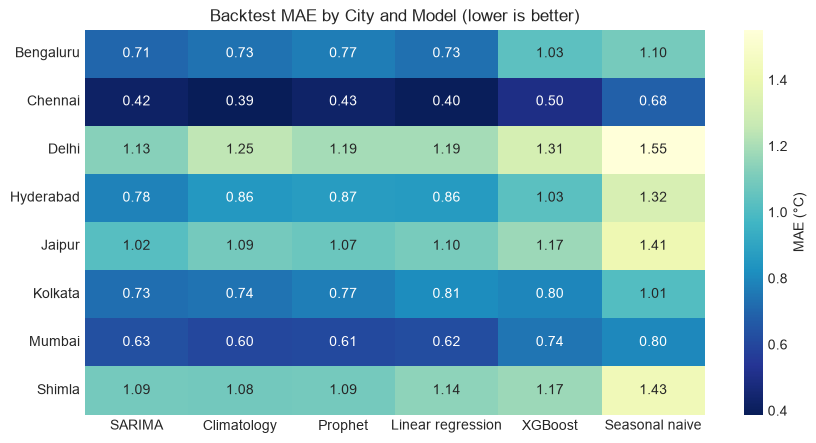

Best model per city (by backtest MAE):
city
Bengaluru         SARIMA
Chennai      Climatology
Delhi             SARIMA
Hyderabad         SARIMA
Jaipur            SARIMA
Kolkata           SARIMA
Mumbai       Climatology
Shimla       Climatology


In [7]:
cv_city = score(cv, ["city", "model"])
mae_grid = cv_city["MAE"].unstack()[list(cv_model.index)]

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(mae_grid, annot=True, fmt=".2f", cmap="YlGnBu_r", cbar_kws={"label": "MAE (°C)"}, ax=ax)
ax.set_title("Backtest MAE by City and Model (lower is better)")
ax.set_ylabel("")
ax.set_xlabel("")
save_fig(fig, "09_cv_mae_heatmap")
plt.show()

best = mae_grid.idxmin(axis=1)
print("Best model per city (by backtest MAE):")
print(best.to_string())

## 7. Final test: 2026
These months were **never** used for training or model selection. We also show "Selected", which uses the best backtest model for each city.

In [8]:
test_sel = test.merge(best.rename("best").reset_index(), on="city")
test_sel = test_sel[test_sel["model"] == test_sel["best"]].assign(group="Selected (best per city)")

test_overall = pd.concat([score(test, "model"), score(test_sel, "group")]).sort_values("MAE")
base = test_overall.loc["Seasonal naive", "MAE"]
test_overall["skill_vs_seasonal_naive_%"] = (1 - test_overall["MAE"] / base) * 100
print(f"Test results, all cities, {n_test} months of 2026:")
test_overall.round(2)

Test results, all cities, 9 months of 2026:


,MAE,RMSE,MAPE,coverage_80,skill_vs_seasonal_naive_%
Selected (best per city),0.81,0.99,3.15,88.89,29.11
Climatology,0.83,1.02,3.26,NaN,27.57
SARIMA,0.83,1.01,3.25,83.33,27.02
Prophet,0.90,1.09,3.59,73.61,21.08
Linear regression,0.91,1.12,3.70,75.00,19.88
XGBoost,0.92,1.19,3.47,NaN,19.20
Seasonal naive,1.14,1.41,4.52,NaN,0.00


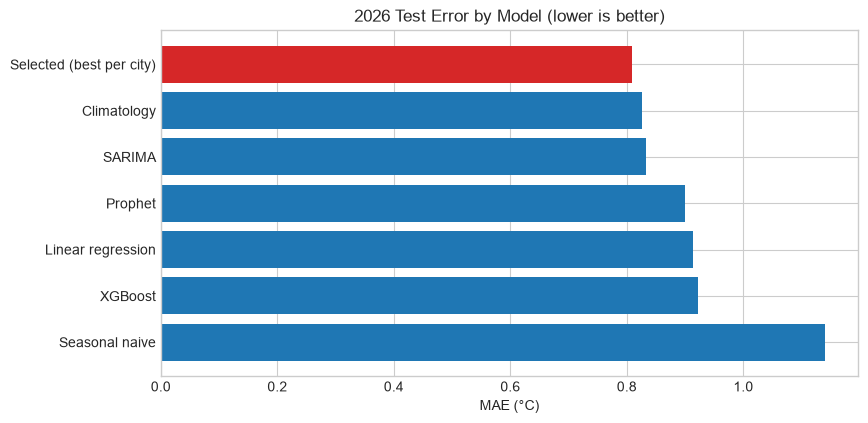

model,SARIMA,Climatology,Prophet,Linear regression,XGBoost,Seasonal naive
city,,,,,,
Bengaluru,1.10,0.98,0.98,1.06,0.96,1.26
Chennai,0.92,0.98,0.92,0.91,0.97,0.87
Delhi,0.72,0.56,0.71,0.93,0.58,0.81
Hyderabad,1.06,1.23,1.36,1.29,1.36,1.75
Jaipur,0.76,0.85,0.87,0.71,0.86,1.32
Kolkata,0.52,0.67,0.86,0.78,0.59,0.75
Mumbai,0.93,0.77,0.83,0.80,1.34,1.24
Shimla,0.66,0.56,0.66,0.83,0.72,1.12


In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_df = test_overall["MAE"].sort_values()
colors = ["#d62728" if "Selected" in m else "#1f77b4" for m in plot_df.index]
ax.barh(plot_df.index, plot_df.values, color=colors)
ax.invert_yaxis()
ax.set_xlabel("MAE (°C)")
ax.set_title("2026 Test Error by Model (lower is better)")
save_fig(fig, "10_test_mae_by_model")
plt.show()

test_city = score(test, ["city", "model"])["MAE"].unstack()[list(cv_model.index)]
test_city.round(2)

### Forecast vs actual for 2026

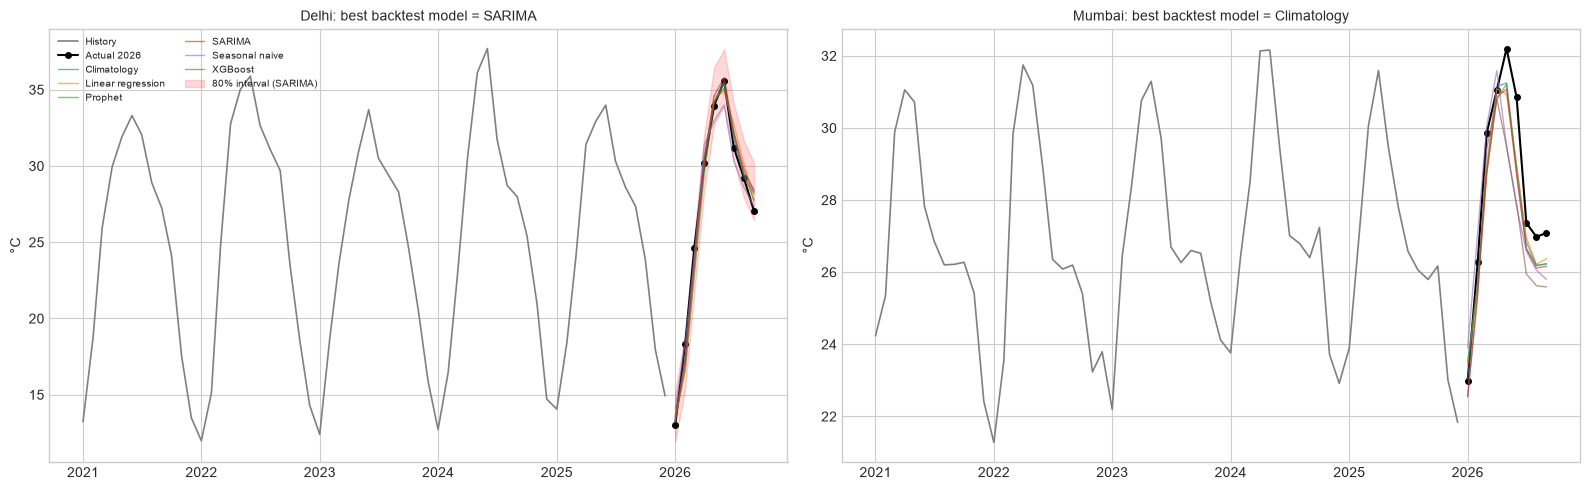

In [10]:
def plot_test(city, ax, history_months=60):
    hist = monthly[city].dropna().loc[:TEST_ORIGIN].iloc[-history_months:]
    t = test[test["city"] == city]
    actual = t.drop_duplicates("date").set_index("date")["y_true"]
    ax.plot(hist.index, hist.values, color="gray", lw=1.2, label="History")
    ax.plot(actual.index, actual.values, "ko-", ms=4, label="Actual 2026")
    for name, g in t.groupby("model"):
        ax.plot(g["date"], g["yhat"], lw=1, alpha=0.6, label=name)
    g = t[t["model"] == best[city]]
    ax.fill_between(g["date"], g["lower"], g["upper"], color="red", alpha=0.15,
                    label=f"80% interval ({best[city]})")
    ax.set_title(f"{city}: best backtest model = {best[city]}", fontsize=10)
    ax.set_ylabel("°C")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, c in zip(axes, ["Delhi", "Mumbai"]):
    if c in monthly.columns:
        plot_test(c, ax)
axes[0].legend(fontsize=7, ncol=2)
fig.tight_layout()
save_fig(fig, "11_test_forecast_delhi_mumbai")
plt.show()

## 8. Are the prediction intervals reliable?
An 80% interval should contain about **80%** of actual values. Much lower means the model is overconfident.

In [11]:
cov = pd.concat({
    "Backtest": score(cv, "model")["coverage_80"],
    "Test 2026": score(test, "model")["coverage_80"],
}, axis=1).dropna(how="all")
print("Share of actual values inside the 80% interval (target ~80%):")
cov.round(1)

Share of actual values inside the 80% interval (target ~80%):


,Backtest,Test 2026
model,,
Linear regression,79.4,75.0
Prophet,77.3,73.6
SARIMA,80.0,83.3


## 9. Forecast the next 12 months
Trained on **all** the data up to the last complete month.

- `FINAL_MODEL = "SARIMA"` uses one well-calibrated model for every city (simple and consistent)
- `FINAL_MODEL = "best"` uses the best backtest model per city
- Models without built-in intervals (Climatology, XGBoost, Seasonal naive) get an **empirical 80% interval** from their own backtest errors, so every city has a band

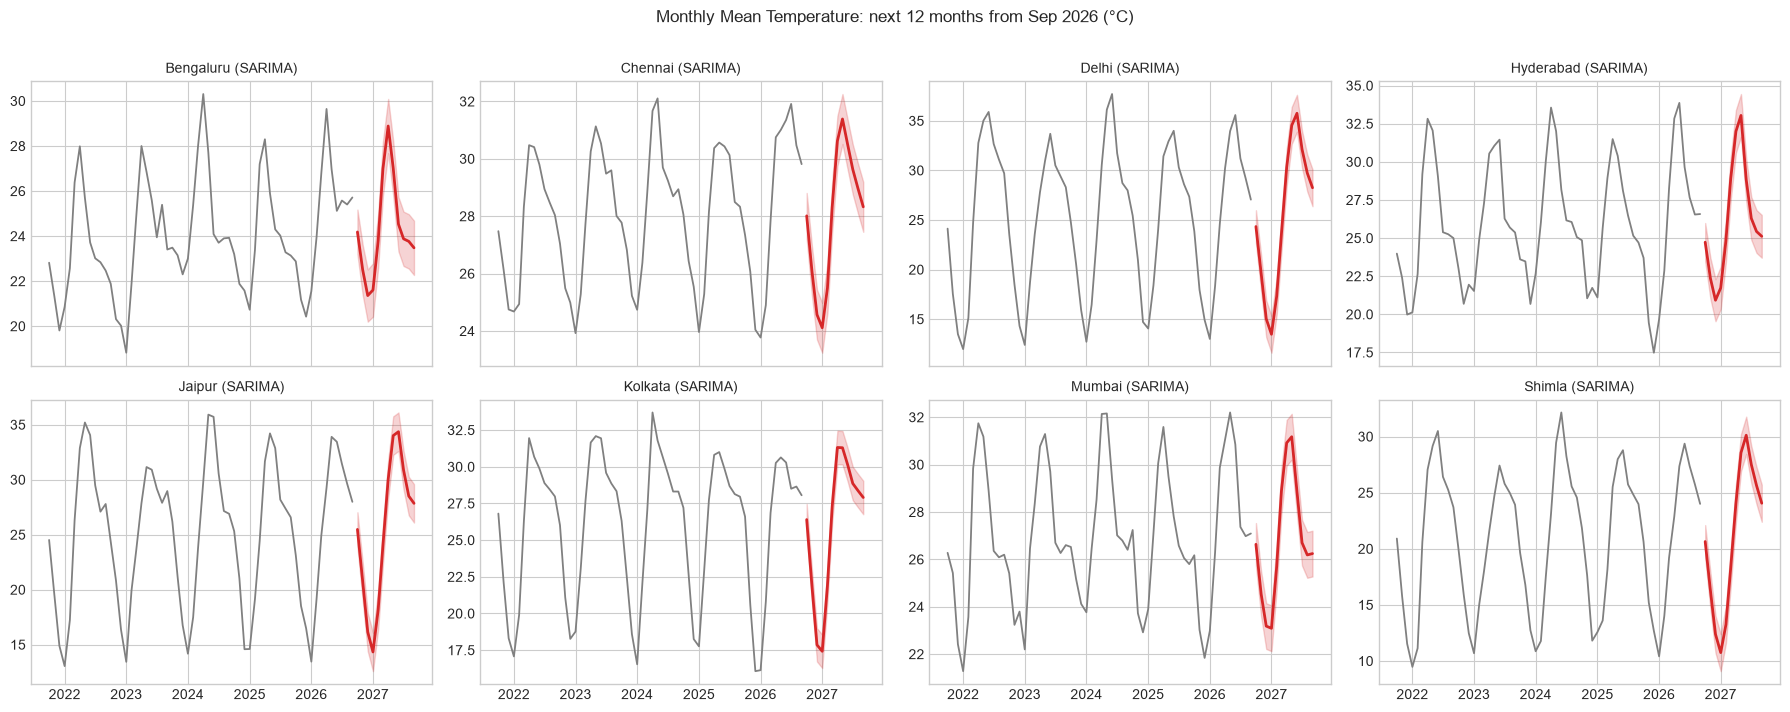

city,Bengaluru,Chennai,Delhi,Hyderabad,Jaipur,Kolkata,Mumbai,Shimla
date,,,,,,,,
2026-10-01,24.2,28.0,24.3,24.7,25.5,26.4,26.6,20.6
2026-11-01,22.5,26.1,19.6,22.4,20.8,21.9,24.5,16.3
2026-12-01,21.4,24.6,15.0,20.9,16.1,17.9,23.2,12.4
2027-01-01,21.6,24.1,13.5,21.7,14.3,17.4,23.1,10.7
2027-02-01,23.8,25.5,17.3,24.9,18.2,21.9,25.7,13.3
2027-03-01,27.0,28.3,23.6,28.9,24.0,27.3,28.9,18.3
2027-04-01,28.9,30.6,30.3,32.0,30.0,31.3,30.9,24.0
2027-05-01,27.0,31.4,34.5,33.0,34.0,31.3,31.2,28.6
2027-06-01,24.5,30.5,35.8,28.8,34.4,30.1,28.9,30.1


In [12]:
FINAL_MODEL = "SARIMA"     # or "best"
final_model = {c: (best[c] if FINAL_MODEL == "best" else FINAL_MODEL) for c in monthly.columns}

# Empirical 80% interval (10th-90th percentile of backtest errors) for models without intervals
err_q = (cv.assign(err=cv["y_true"] - cv["yhat"])
           .groupby(["city", "model"])["err"].quantile([0.1, 0.9]).unstack())

final_rows = []
for city in monthly.columns:
    s = monthly[city].dropna()
    m = final_model[city]
    f = MODELS[m](s, 12)
    if f["lower"].isna().all():
        f["lower"] = f["yhat"] + err_q.loc[(city, m), 0.1]
        f["upper"] = f["yhat"] + err_q.loc[(city, m), 0.9]
    final_rows.append(f.assign(city=city, model=m).rename_axis("date").reset_index())
forecast = pd.concat(final_rows, ignore_index=True)

fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharex=True)
for ax, city in zip(axes.ravel(), monthly.columns):
    hist = monthly[city].dropna().iloc[-60:]
    g = forecast[forecast["city"] == city]
    ax.plot(hist.index, hist.values, color="gray", lw=1.3)
    ax.plot(g["date"], g["yhat"], color="#d62728", lw=2)
    ax.fill_between(g["date"], g["lower"], g["upper"], color="#d62728", alpha=0.2)
    ax.set_title(f"{city} ({final_model[city]})", fontsize=10)
for ax in axes.ravel()[len(monthly.columns):]:
    ax.axis("off")
fig.suptitle(f"Monthly Mean Temperature: next 12 months from {monthly.index.max().strftime('%b %Y')} (°C)", y=1.01)
fig.tight_layout()
save_fig(fig, "12_next_12_months_forecast")
plt.show()

forecast.pivot(index="date", columns="city", values="yhat").round(1)

## 10. Save results
These files are used by the Streamlit app in the next step.

In [13]:
REPORT_DIR.mkdir(exist_ok=True)
forecast.to_csv(REPORT_DIR / "forecast_next_12_months.csv", index=False)
cv_city.round(4).to_csv(REPORT_DIR / "metrics_backtest_by_city.csv")
score(test, ["city", "model"]).round(4).to_csv(REPORT_DIR / "metrics_test_2026_by_city.csv")
test_overall.round(4).to_csv(REPORT_DIR / "metrics_test_2026_overall.csv")
pd.DataFrame({"best_backtest_model": best, "final_model_used": pd.Series(final_model)}).to_csv(REPORT_DIR / "best_model_per_city.csv")
print("Saved to", REPORT_DIR.resolve())
sorted(p.name for p in REPORT_DIR.glob("*.csv"))

Saved to D:\INternship\india-weather-forecast\india-weather-forecast\reports


['best_model_per_city.csv',
 'forecast_next_12_months.csv',
 'metrics_backtest_by_city.csv',
 'metrics_test_2026_by_city.csv',
 'metrics_test_2026_overall.csv']